In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# ============================================================
# CELL 3 — Login to HuggingFace
# ============================================================
from huggingface_hub import login
login()  # paste your HF token when prompted

In [3]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
 
model_id = "allenai/OLMoE-1B-7B-0924-Instruct"
 
print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(model_id)
 
print("Loading model... (1-2 minutes)")
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)
model.eval()
 
print("\nLoaded successfully!")
print(f"Memory used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
print(f"Model type: {type(model).__name__}")

Loading tokenizer...


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/433 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/120 [00:00<?, ?B/s]


Loaded successfully!
Memory used: 6.92 GB
Model type: OlmoeForCausalLM


In [4]:
print("MoE-related layers:\n")
router_layers = []
for name, module in model.named_modules():
    if any(x in name.lower() for x in ["router", "gate", "expert"]):
        print(f"  {name}  →  {type(module).__name__}")
        if "router" in name.lower():
            router_layers.append(name)
 
print(f"\nTotal router layers: {len(router_layers)}")
print(f"Example: {router_layers[0] if router_layers else 'none found'}")

MoE-related layers:

  model.layers.0.mlp.gate  →  OlmoeTopKRouter
  model.layers.0.mlp.experts  →  OlmoeExperts
  model.layers.0.mlp.experts.act_fn  →  SiLUActivation
  model.layers.1.mlp.gate  →  OlmoeTopKRouter
  model.layers.1.mlp.experts  →  OlmoeExperts
  model.layers.1.mlp.experts.act_fn  →  SiLUActivation
  model.layers.2.mlp.gate  →  OlmoeTopKRouter
  model.layers.2.mlp.experts  →  OlmoeExperts
  model.layers.2.mlp.experts.act_fn  →  SiLUActivation
  model.layers.3.mlp.gate  →  OlmoeTopKRouter
  model.layers.3.mlp.experts  →  OlmoeExperts
  model.layers.3.mlp.experts.act_fn  →  SiLUActivation
  model.layers.4.mlp.gate  →  OlmoeTopKRouter
  model.layers.4.mlp.experts  →  OlmoeExperts
  model.layers.4.mlp.experts.act_fn  →  SiLUActivation
  model.layers.5.mlp.gate  →  OlmoeTopKRouter
  model.layers.5.mlp.experts  →  OlmoeExperts
  model.layers.5.mlp.experts.act_fn  →  SiLUActivation
  model.layers.6.mlp.gate  →  OlmoeTopKRouter
  model.layers.6.mlp.experts  →  OlmoeExperts
  mod

In [5]:
# CELL 4 — Fixed hook setup
import numpy as np

_current_routing = {}

def make_hook(layer_idx):
    def hook_fn(module, input, output):
        if isinstance(output, tuple):
            logits = output[0]
        else:
            logits = output

        logits_float = logits.detach().cpu().float()
        _current_routing[layer_idx] = logits_float.mean(dim=0).numpy()

    return hook_fn

# Fixed: "gate" instead of "router"
hooks = []
hooked_count = 0
for name, module in model.named_modules():
    if "mlp.gate" in name.lower():          # ← changed from "router" to "mlp.gate"
        h = module.register_forward_hook(make_hook(hooked_count))
        hooks.append(h)
        hooked_count += 1

N_LAYERS  = hooked_count
N_EXPERTS = 64

print(f"Hooked {N_LAYERS} router layers")   # should print 16
print(f"Each layer has {N_EXPERTS} experts")

Hooked 16 router layers
Each layer has 64 experts


In [6]:
from datasets import load_dataset
 
prompts = []
 
def add_prompts(items, task_type):
    for p in items:
        prompts.append({"prompt": p, "task_type": task_type})
 
# Math
print("Loading GSM8K...")
ds = load_dataset("gsm8k", "main", split="train[:600]")
add_prompts([x["question"] for x in ds], "math")
 
# Code
print("Loading HumanEval...")
ds = load_dataset("openai_humaneval", split="test")
add_prompts([x["prompt"] for x in ds], "code")
 
# Reasoning / MMLU
print("Loading MMLU...")
ds = load_dataset("cais/mmlu", "all", split="test[:600]")
add_prompts([x["question"] for x in ds], "reasoning")
 
# Chat
# Replace the DailyDialog cell with this
print("Loading OpenHermes chat...")
ds = load_dataset("teknium/OpenHermes-2.5", split="train[:500]")
add_prompts([x["conversations"][0]["value"] for x in ds], "chat")
 
# Factual QA
print("Loading TriviaQA...")
ds = load_dataset("trivia_qa", "rc", split="train[:400]")
add_prompts([x["question"] for x in ds], "factual")
 
import random
random.shuffle(prompts)
 
print(f"\nTotal prompts: {len(prompts)}")
task_counts = {}
for p in prompts:
    task_counts[p["task_type"]] = task_counts.get(p["task_type"], 0) + 1
print("Per task type:", task_counts)

Loading GSM8K...


README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

... (57 outputs left out)

Generating train split:   0%|          | 0/138384 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/17944 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/17210 [00:00<?, ? examples/s]


Total prompts: 2264
Per task type: {'chat': 500, 'math': 600, 'code': 164, 'reasoning': 600, 'factual': 400}


In [8]:
import json, os
from tqdm import tqdm
 
SAVE_DIR    = "/kaggle/working/"
CHECKPOINT  = os.path.join(SAVE_DIR, "routing_dataset_checkpoint.json")
FINAL_PATH  = os.path.join(SAVE_DIR, "routing_dataset_final.json")
 
collected = []
failed    = 0
 
for i, item in enumerate(tqdm(prompts, desc="Collecting")):
    try:
        _current_routing.clear()
 
        inputs = tokenizer(
            item["prompt"],
            return_tensors="pt",
            truncation=True,
            max_length=256,
            padding=False,
        ).to(model.device)
 
        with torch.no_grad():
            model(**inputs)
 
        # Check all layers captured
        if len(_current_routing) != N_LAYERS:
            failed += 1
            continue
 
        # Stack into (N_LAYERS, N_EXPERTS)
        routing_matrix = np.stack(
            [_current_routing[l] for l in range(N_LAYERS)]
        )  # shape: (N_LAYERS, N_EXPERTS)
 
        collected.append({
            "prompt":              item["prompt"],
            "task_type":           item["task_type"],
            # Full per-layer routing: list of N_LAYERS lists, each length N_EXPERTS
            "routing_logits":      routing_matrix.tolist(),
            # Mean across layers → single (N_EXPERTS,) vector used by predictor
            "mean_routing_logits": routing_matrix.mean(axis=0).tolist(),
            # Top-2 experts per layer (ground truth routing decisions)
            "top2_experts":        np.argsort(routing_matrix, axis=1)[:, -2:].tolist(),
        })
 
        # Checkpoint every 200 samples so you don't lose progress
        if (i + 1) % 200 == 0:
            with open(CHECKPOINT, "w") as f:
                json.dump(collected, f)
            print(f"  Checkpoint: {len(collected)} collected, {failed} failed")
 
    except Exception as e:
        failed += 1
        continue
 
# Remove hooks — important, don't skip this
for h in hooks:
    h.remove()
 
# Save final
with open(FINAL_PATH, "w") as f:
    json.dump(collected, f)
 
print(f"\nDone.")
print(f"  Collected : {len(collected)}")
print(f"  Failed    : {failed}")
print(f"  Saved to  : {FINAL_PATH}")
print(f"  File size : {os.path.getsize(FINAL_PATH) / 1e6:.1f} MB")

Collecting:   9%|▉         | 200/2264 [01:17<12:03,  2.85it/s]

  Checkpoint: 200 collected, 0 failed


Collecting:  18%|█▊        | 400/2264 [02:34<15:26,  2.01it/s]

  Checkpoint: 400 collected, 0 failed


Collecting:  27%|██▋       | 600/2264 [03:50<18:12,  1.52it/s]

  Checkpoint: 600 collected, 0 failed


... (14 outputs left out)

Collecting:  97%|█████████▋| 2200/2264 [14:05<01:17,  1.21s/it]

  Checkpoint: 2200 collected, 0 failed


Collecting: 100%|██████████| 2264/2264 [14:29<00:00,  2.60it/s]



Done.
  Collected : 2264
  Failed    : 0
  Saved to  : /kaggle/working/routing_dataset_final.json
  File size : 54.7 MB


Total samples: 2264
Keys: ['prompt', 'task_type', 'routing_logits', 'mean_routing_logits', 'top2_experts']
Routing logits shape per sample: (16, 64)

Task distribution: {'chat': 500, 'math': 600, 'code': 164, 'reasoning': 600, 'factual': 400}

Mean routing logit variance per task (higher = more diversity):
  chat        : 0.0000
  math        : 0.0000
  code        : 0.0000
  reasoning   : 0.0000
  factual     : 0.0000


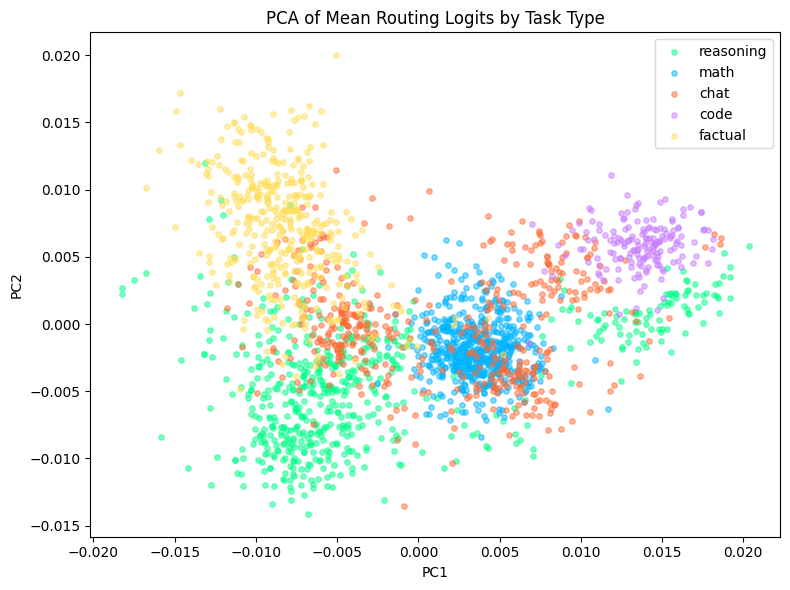

If clusters are visually separated → routing is task-specific → predictor will work well


In [9]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
 
# Load (in case you're starting a new session)
with open(FINAL_PATH) as f:
    data = json.load(f)
 
print(f"Total samples: {len(data)}")
print(f"Keys: {list(data[0].keys())}")
print(f"Routing logits shape per sample: ({len(data[0]['routing_logits'])}, {len(data[0]['routing_logits'][0])})")
 
# Task distribution
task_counts = {}
for d in data:
    task_counts[d["task_type"]] = task_counts.get(d["task_type"], 0) + 1
print(f"\nTask distribution: {task_counts}")
 
# Check routing diversity — if all task types have similar routing, predictor won't learn much
mean_logits_by_task = {}
for d in data:
    t = d["task_type"]
    if t not in mean_logits_by_task:
        mean_logits_by_task[t] = []
    mean_logits_by_task[t].append(d["mean_routing_logits"])
 
print("\nMean routing logit variance per task (higher = more diversity):")
for task, logits in mean_logits_by_task.items():
    arr = np.array(logits)
    print(f"  {task:12s}: {arr.var(axis=0).mean():.4f}")
 
# PCA plot — task types should form distinct clusters
all_logits = np.array([d["mean_routing_logits"] for d in data])
all_tasks  = [d["task_type"] for d in data]
task_labels = list(set(all_tasks))
colors = ["#00ff88", "#00b4ff", "#ff6b35", "#c77dff", "#ffdd57"]
 
pca = PCA(n_components=2)
reduced = pca.fit_transform(all_logits)
 
plt.figure(figsize=(8, 6))
for i, task in enumerate(task_labels):
    idx = [j for j, t in enumerate(all_tasks) if t == task]
    plt.scatter(reduced[idx, 0], reduced[idx, 1],
                label=task, alpha=0.5, s=15, color=colors[i % len(colors)])
plt.legend()
plt.title("PCA of Mean Routing Logits by Task Type")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "routing_pca.png"))
plt.show()
print("If clusters are visually separated → routing is task-specific → predictor will work well")
 

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
 
# --- Dataset ---
class RoutingDataset(Dataset):
    def __init__(self, samples):
        # Input: mean routing logits (N_EXPERTS,)
        # Target: mean routing logits (same — predictor learns to reproduce from prompt)
        # In production you'd use prompt embeddings as input
        # Here we use the logits themselves as a sanity-check baseline
        self.X = torch.tensor(
            [s["mean_routing_logits"] for s in samples], dtype=torch.float32
        )
        self.Y = self.X.clone()
 
    def __len__(self):
        return len(self.X)
 
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]
 
 
# NOTE: In the real pipeline, replace self.X with prompt embeddings
# from a tiny encoder (e.g. mean-pool tokenizer embeddings)
# For now this validates that the MLP architecture and training loop work
 
def get_prompt_embedding(prompt, tokenizer, model, max_len=64):
    """
    Cheap prompt embedding: mean pool last hidden state over tokens.
    Use this as input to predictor instead of raw routing logits.
    """
    inputs = tokenizer(
        prompt, return_tensors="pt",
        truncation=True, max_length=max_len
    ).to(model.device)
 
    with torch.no_grad():
        out = model(**inputs, output_hidden_states=True)
 
    # Last hidden state: (1, seq_len, hidden_dim) → mean → (hidden_dim,)
    embedding = out.hidden_states[-1][0].mean(dim=0).cpu().float()
    return embedding
 
 
# --- Predictor MLP ---
class RoutingPredictor(nn.Module):
    def __init__(self, input_dim, n_experts):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, n_experts),
        )
 
    def forward(self, x):
        return self.net(x)
 
 
# --- Training ---
HIDDEN_DIM = model.config.hidden_size  # OLMoE hidden dim
predictor  = RoutingPredictor(input_dim=HIDDEN_DIM, n_experts=N_EXPERTS)
 
# Collect embeddings for all samples
print("Collecting prompt embeddings for predictor training...")
embeddings = []
targets    = []
 
for sample in tqdm(data, desc="Embedding"):
    emb = get_prompt_embedding(sample["prompt"], tokenizer, model)
    embeddings.append(emb)
    targets.append(torch.tensor(sample["mean_routing_logits"], dtype=torch.float32))
 
X_all = torch.stack(embeddings)   # (N, hidden_dim)
Y_all = torch.stack(targets)       # (N, N_EXPERTS)
 
# Normalize targets
Y_mean = Y_all.mean(dim=0)
Y_std  = Y_all.std(dim=0) + 1e-8
Y_all_norm = (Y_all - Y_mean) / Y_std
 
# Train / val split
X_train, X_val, Y_train, Y_val = train_test_split(
    X_all, Y_all_norm, test_size=0.15, random_state=42
)
 
train_loader = DataLoader(
    list(zip(X_train, Y_train)), batch_size=64, shuffle=True
)
val_loader = DataLoader(
    list(zip(X_val, Y_val)), batch_size=64
)
 
optimizer = torch.optim.AdamW(predictor.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
criterion = nn.MSELoss()
 
predictor.train()
best_val_loss = float("inf")
 
print("\nTraining routing predictor...")
for epoch in range(60):
    # Train
    train_loss = 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        pred = predictor(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(predictor.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item()
 
    scheduler.step()
 
    # Validate
    predictor.eval()
    val_loss = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            val_loss += criterion(predictor(xb), yb).item()
    predictor.train()
 
    train_loss /= len(train_loader)
    val_loss   /= len(val_loader)
 
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(predictor.state_dict(),
                   os.path.join(SAVE_DIR, "routing_predictor_best.pt"))
 
    if (epoch + 1) % 10 == 0:
        print(f"  Epoch {epoch+1:3d} | train {train_loss:.4f} | val {val_loss:.4f}")
 
print(f"\nBest val loss: {best_val_loss:.4f}")
print(f"Predictor saved to {SAVE_DIR}routing_predictor_best.pt")
 
# Top-K overlap metric — what % of time do we predict the right top experts?
predictor.eval()
with torch.no_grad():
    preds = predictor(X_val) * Y_std + Y_mean   # denormalize
    trues = Y_val * Y_std + Y_mean
 
K = 4
pred_topk = preds.topk(K, dim=1).indices
true_topk = trues.topk(K, dim=1).indices
 
overlaps = []
for p, t in zip(pred_topk, true_topk):
    overlap = len(set(p.tolist()) & set(t.tolist())) / K
    overlaps.append(overlap)
 
print(f"Top-{K} expert overlap: {np.mean(overlaps)*100:.1f}%  (target: >60%)")
 

Embedding:  84%|████████▍ | 1898/2264 [11:27<02:12,  2.76it/s]

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import random
 
TIER_FULL      = 0   # fp16
TIER_BALANCED  = 1   # fp8
TIER_MINIMAL   = 2   # fp4
 
# Memory cost per expert per tier (GB, approximate for OLMoE expert size)
MEMORY_COST = {
    TIER_FULL:     0.012,   # fp16
    TIER_BALANCED: 0.006,   # fp8
    TIER_MINIMAL:  0.003,   # fp4
}
 
# Energy cost per expert per tier (relative units)
ENERGY_COST = {
    TIER_FULL:     1.0,
    TIER_BALANCED: 0.6,
    TIER_MINIMAL:  0.3,
}
 
# Quality penalty when downgrading (perplexity delta, normalized 0-1)
# Derived from your dataset — here using reasonable estimates
# Replace with real measurements once you collect fp8/fp4 perplexity data
QUALITY_PENALTY = {
    TIER_FULL:     0.00,
    TIER_BALANCED: 0.05,
    TIER_MINIMAL:  0.25,
}
 
 
class HardwareSimulator:
    """Simulates battery and RAM state over a conversation session."""
 
    def __init__(self):
        self.battery   = 100.0
        self.ram_free  = 8.0    # GB
        self.thermal   = 0.0    # 0=normal, 1=throttling
        self.drain_rate = 0.0
 
    def reset(self, battery_start=None):
        self.battery    = battery_start or float(np.random.randint(20, 100))
        self.ram_free   = float(np.random.uniform(2.0, 7.0))
        self.thermal    = 0.0
        self.drain_rate = float(np.random.uniform(0.05, 0.20))  # % per turn
        return self._state()
 
    def step(self, action_energy_cost):
        # Drain battery proportional to energy used
        self.battery  -= self.drain_rate * (1 + action_energy_cost)
        self.battery   = max(self.battery, 0.0)
 
        # RAM fluctuates slightly (background apps)
        self.ram_free += np.random.uniform(-0.2, 0.1)
        self.ram_free  = np.clip(self.ram_free, 0.0, 8.0)
 
        # Thermal throttle if battery drain rate is high
        self.thermal = 1.0 if self.drain_rate > 0.15 else 0.0
 
        return self._state()
 
    def _state(self):
        return {
            "battery":    self.battery,
            "ram_free":   self.ram_free,
            "thermal":    self.thermal,
            "drain_rate": self.drain_rate,
        }
 
    def is_terminal(self):
        return self.battery < 2.0 or self.ram_free < 0.3
 
 
class AdaptiveMoEEnv(gym.Env):
    """
    RL environment for adaptive per-expert quantization.
 
    State  : [mean_routing_logits (N_EXPERTS,), battery, ram_free, drain_rate, thermal]
    Action : tier per expert — MultiDiscrete([3] * N_EXPERTS)
             0=FULL(fp16), 1=BALANCED(fp8), 2=MINIMAL(fp4)
    Reward : α·mem_saved + β·energy_saved − γ·quality_penalty − δ·switch_cost
    """
 
    def __init__(self, data, hw_sim, n_experts=64, max_turns=40):
        super().__init__()
        self.data      = data
        self.hw_sim    = hw_sim
        self.n_experts = n_experts
        self.max_turns = max_turns
 
        # State space
        obs_dim = n_experts + 4  # routing logits + battery + ram + drain + thermal
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32
        )
 
        # Action space: one tier decision per expert
        self.action_space = spaces.MultiDiscrete([3] * n_experts)
 
        self._prev_action = None
 
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.turn        = 0
        self.sample      = random.choice(self.data)
        self.hw_state    = self.hw_sim.reset()
        self._prev_action = None
        return self._obs(), {}
 
    def step(self, action):
        action = np.array(action)
        hw     = self.hw_state
 
        # ── Routing relevance per expert ──────────────────────────
        routing = np.array(self.sample["mean_routing_logits"])
        # Softmax to get importance weights (0-1)
        exp_r   = np.exp(routing - routing.max())
        importance = exp_r / exp_r.sum()  # (N_EXPERTS,)
 
        # ── Memory saved ──────────────────────────────────────────
        mem_used     = sum(MEMORY_COST[a] for a in action)
        mem_baseline = MEMORY_COST[TIER_FULL] * self.n_experts
        mem_saved    = (mem_baseline - mem_used) / mem_baseline  # 0-1
 
        # ── Energy saved ──────────────────────────────────────────
        energy_used     = sum(ENERGY_COST[a] for a in action)
        energy_baseline = ENERGY_COST[TIER_FULL] * self.n_experts
        energy_saved    = (energy_baseline - energy_used) / energy_baseline  # 0-1
 
        # ── Quality penalty ───────────────────────────────────────
        # Weighted by expert importance: degrading an important expert costs more
        quality_loss = sum(
            importance[i] * QUALITY_PENALTY[action[i]]
            for i in range(self.n_experts)
        )  # 0-1 range
 
        # ── Switch cost ───────────────────────────────────────────
        if self._prev_action is not None:
            switches    = np.sum(action != self._prev_action)
            switch_cost = switches / self.n_experts  # normalized 0-1
        else:
            switch_cost = 0.0
 
        # ── Advance state ─────────────────────────────────────────
        self._prev_action = action.copy()
        self.hw_state     = self.hw_sim.step(energy_used / energy_baseline)
        self.sample       = random.choice(self.data)
        self.turn        += 1
 
        terminated = self.hw_sim.is_terminal()
        truncated  = self.turn >= self.max_turns

        # ── Structural Survival & Terminal Logic ──────────────────
        if terminated:
            survival_bonus = 0.0
            terminal_penalty = 20.0  # Massive hit for letting the device crash
        else:
            survival_bonus = 1.0     # Flat +1.0 just for surviving the turn
            terminal_penalty = 0.0
 
        # ── Reward ────────────────────────────────────────────────
        alpha = 0.38
        gamma = 0.40
        delta = 0.10
        
        # Dynamic Beta: Energy becomes exponentially more valuable as battery drops
        current_battery_ratio = hw["battery"] / 100.0
        beta = 0.25 + (1.0 - current_battery_ratio) * 0.50
        reward = (
            alpha * mem_saved
          + beta  * energy_saved
          - gamma * quality_loss
          - delta * switch_cost
          + 0.05  * survival_bonus   # Flat reward, no longer scaled by battery %
          - terminal_penalty         # Forces the agent to care about hitting 0%
        )
 
        info = {
            "mem_saved":    mem_saved,
            "energy_saved": energy_saved,
            "quality_loss": quality_loss,
            "switch_cost":  switch_cost,
            "battery":      self.hw_state["battery"], # Updated to reflect advanced state
        }
 
        return self._obs(), reward, terminated, truncated, info
 
    def _obs(self):
        routing = np.array(self.sample["mean_routing_logits"], dtype=np.float32)
        hw      = self.hw_state
        hw_vec  = np.array([
            hw["battery"]   / 100.0,
            hw["ram_free"]  / 8.0,
            hw["drain_rate"],
            hw["thermal"],
        ], dtype=np.float32)
        return np.concatenate([routing, hw_vec])

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import EvalCallback, CheckpointCallback
from stable_baselines3.common.monitor import Monitor
import torch
import json
import os

# Load dataset (in case starting fresh session)
with open(FINAL_PATH) as f:
    data = json.load(f)

hw_sim = HardwareSimulator()

# Wrap in Monitor for logging
def make_env():
    env = AdaptiveMoEEnv(data, HardwareSimulator(), n_experts=N_EXPERTS)
    return Monitor(env)

# Vectorized environments for faster training
n_envs = 4
vec_env = make_vec_env(make_env, n_envs=n_envs)

# Eval environment
eval_env = Monitor(AdaptiveMoEEnv(data, HardwareSimulator(), n_experts=N_EXPERTS))

# Callbacks
eval_callback = EvalCallback(
    eval_env,
    best_model_save_path=SAVE_DIR,
    log_path=SAVE_DIR,
    eval_freq=5000,
    n_eval_episodes=20,
    deterministic=True,
    verbose=1,
)

checkpoint_callback = CheckpointCallback(
    save_freq=10000,
    save_path=SAVE_DIR,
    name_prefix="rl_agent",
)

# PPO agent — small MLP policy (keep it tiny for on-device deployment)
model_rl = PPO(
    "MlpPolicy",
    vec_env,
    policy_kwargs=dict(
        net_arch=[384, 192],    # Increased capacity handles the 68-dim input to 64-dim output map
        activation_fn=torch.nn.ReLU,
    ),
    learning_rate=1e-4,
    n_steps=1024,
    batch_size=512,             # Keeps variance low across noisy multi-discrete actions
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.001,            # Bounded: 0.0008 * 70.3 ≈ -0.056 (perfectly scales with policy gradient)
    target_kl=0.015,            # Safety brake: prevents policy updates from becoming unstable
    vf_coef=0.5,
    max_grad_norm=0.5,
    verbose=1,
    tensorboard_log=os.path.join(SAVE_DIR, "tb_logs/"),
)

print("Training RL agent...")
print("Expected time: ~20-40 minutes on CPU/GPU\n")

model_rl.learn(
    total_timesteps=250_000,
    callback=[eval_callback, checkpoint_callback],
    progress_bar=False,         # Correctly disabled to bypass Jupyter display bugs
)

model_rl.save(os.path.join(SAVE_DIR, "rl_agent_final"))
print(f"\nAgent saved to {SAVE_DIR}rl_agent_final")

In [ ]:
from stable_baselines3 import PPO
import pandas as pd
 
# Load best agent
agent = PPO.load(os.path.join(SAVE_DIR, "best_model"))
 
# Test across different battery levels
battery_levels = [100, 75, 50, 25, 10]
results = []
 
for bat in battery_levels:
    env = AdaptiveMoEEnv(data, HardwareSimulator(), n_experts=N_EXPERTS)
    obs, _ = env.reset()
    env.hw_sim.battery = float(bat)  # override starting battery
    obs = env._obs()
 
    ep_rewards    = []
    ep_mem_saved  = []
    ep_energy     = []
    ep_quality    = []
 
    for _ in range(30):  # 30 turns per episode
        action, _ = agent.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        ep_rewards.append(reward)
        ep_mem_saved.append(info["mem_saved"])
        ep_energy.append(info["energy_saved"])
        ep_quality.append(info["quality_loss"])
        if terminated or truncated:
            break
 
    results.append({
        "battery_start_%": bat,
        "avg_reward":       np.mean(ep_rewards),
        "avg_mem_saved_%":  np.mean(ep_mem_saved) * 100,
        "avg_energy_saved_%": np.mean(ep_energy) * 100,
        "avg_quality_loss": np.mean(ep_quality),
        "turns_survived":   len(ep_rewards),
    })
 
df = pd.DataFrame(results)
print("\n=== Agent Evaluation Results ===")
print(df.to_string(index=False))
 
# Visualize
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
 
axes[0].plot(df["battery_start_%"], df["avg_mem_saved_%"], "o-", color="#00ff88")
axes[0].set_title("Memory Saved vs Battery Level")
axes[0].set_xlabel("Starting Battery %")
axes[0].set_ylabel("Memory Saved %")
axes[0].grid(alpha=0.3)
 
axes[1].plot(df["battery_start_%"], df["avg_energy_saved_%"], "o-", color="#00b4ff")
axes[1].set_title("Energy Saved vs Battery Level")
axes[1].set_xlabel("Starting Battery %")
axes[1].set_ylabel("Energy Saved %")
axes[1].grid(alpha=0.3)
 
axes[2].plot(df["battery_start_%"], df["avg_quality_loss"], "o-", color="#ff6b35")
axes[2].set_title("Quality Loss vs Battery Level")
axes[2].set_xlabel("Starting Battery %")
axes[2].set_ylabel("Quality Loss (lower=better)")
axes[2].grid(alpha=0.3)
 
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "agent_evaluation.png"))
plt.show()
 
print("\nKey claim to validate:")
print("At low battery → agent should save more memory/energy with acceptable quality loss")
print("At full battery → agent should prioritize quality over savings")

In [ ]:
# ============================================================
# CELL 12 — Baseline Comparisons
# ============================================================

def run_baseline(data, policy, n_episodes=50, battery_start=None):
    """
    policy: "always_full"    → all experts TIER_FULL (fp16)
            "always_balanced" → all experts TIER_BALANCED (fp8)
            "always_minimal"  → all experts TIER_MINIMAL (fp4)
            "rl_agent"        → trained PPO agent
    """
    results = []

    for _ in range(n_episodes):
        env = AdaptiveMoEEnv(data, HardwareSimulator(), n_experts=N_EXPERTS)
        obs, _ = env.reset()

        if battery_start is not None:
            env.hw_sim.battery = float(battery_start)
            obs = env._obs()

        ep_rewards    = []
        ep_mem_saved  = []
        ep_energy     = []
        ep_quality    = []
        ep_battery    = []
        turns_alive   = 0

        for _ in range(40):
            # Select action based on policy
            if policy == "always_full":
                action = np.zeros(N_EXPERTS, dtype=int)       # all TIER_FULL

            elif policy == "always_balanced":
                action = np.ones(N_EXPERTS, dtype=int)        # all TIER_BALANCED

            elif policy == "always_minimal":
                action = np.full(N_EXPERTS, 2, dtype=int)     # all TIER_MINIMAL

            elif policy == "rl_agent":
                action, _ = agent.predict(obs, deterministic=True)

            obs, reward, terminated, truncated, info = env.step(action)

            ep_rewards.append(reward)
            ep_mem_saved.append(info["mem_saved"])
            ep_energy.append(info["energy_saved"])
            ep_quality.append(info["quality_loss"])
            ep_battery.append(info["battery"])
            turns_alive += 1

            if terminated or truncated:
                break

        results.append({
            "avg_reward":       np.mean(ep_rewards),
            "avg_mem_saved":    np.mean(ep_mem_saved) * 100,
            "avg_energy_saved": np.mean(ep_energy) * 100,
            "avg_quality_loss": np.mean(ep_quality),
            "turns_survived":   turns_alive,
            "battery_end":      ep_battery[-1] if ep_battery else 0,
        })

    # Average across episodes
    return {k: np.mean([r[k] for r in results]) for k in results[0]}


# ── Run all baselines across battery levels ───────────────────────────────
policies = {
    "FP16 (always full)":     "always_full",
    "FP8 (always balanced)":  "always_balanced",
    "FP4 (always minimal)":   "always_minimal",
    "RL Agent (ours)":        "rl_agent",
}

battery_levels = [100, 75, 50, 25, 10]
all_results = {}

print("Running comparisons... (this takes ~2 minutes)\n")
for label, policy in policies.items():
    all_results[label] = []
    for bat in battery_levels:
        r = run_baseline(data, policy, n_episodes=30, battery_start=bat)
        all_results[label].append(r)
    print(f"  Done: {label}")


# ── Table ─────────────────────────────────────────────────────────────────
print("\n" + "="*75)
print(f"{'Policy':<25} | {'Mem Saved%':>10} | {'Energy%':>8} | {'Quality↓':>9} | {'Turns':>6}")
print("="*75)

for label in policies:
    # Average across all battery levels
    avg = {k: np.mean([r[k] for r in all_results[label]]) for k in all_results[label][0]}
    print(f"{label:<25} | {avg['avg_mem_saved']:>9.1f}% | {avg['avg_energy_saved']:>7.1f}% | {avg['avg_quality_loss']:>9.4f} | {avg['turns_survived']:>5.1f}")

print("="*75)


# ── Plots ─────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, :])

colors = {
    "FP16 (always full)":     "#ff4d4d",
    "FP8 (always balanced)":  "#ffaa00",
    "FP4 (always minimal)":   "#4da6ff",
    "RL Agent (ours)":        "#00ff88",
}
markers = {
    "FP16 (always full)":     "s",
    "FP8 (always balanced)":  "^",
    "FP4 (always minimal)":   "D",
    "RL Agent (ours)":        "o",
}

# Plot 1: Memory saved vs battery
for label in policies:
    vals = [r["avg_mem_saved"] for r in all_results[label]]
    ax1.plot(battery_levels, vals,
             color=colors[label], marker=markers[label],
             linewidth=2, markersize=6, label=label)
ax1.set_title("Memory Saved %", fontweight="bold")
ax1.set_xlabel("Starting Battery %")
ax1.set_ylabel("Memory Saved %")
ax1.legend(fontsize=7)
ax1.grid(alpha=0.3)

# Plot 2: Energy saved vs battery
for label in policies:
    vals = [r["avg_energy_saved"] for r in all_results[label]]
    ax2.plot(battery_levels, vals,
             color=colors[label], marker=markers[label],
             linewidth=2, markersize=6, label=label)
ax2.set_title("Energy Saved %", fontweight="bold")
ax2.set_xlabel("Starting Battery %")
ax2.set_ylabel("Energy Saved %")
ax2.legend(fontsize=7)
ax2.grid(alpha=0.3)

# Plot 3: Quality loss vs battery
for label in policies:
    vals = [r["avg_quality_loss"] for r in all_results[label]]
    ax3.plot(battery_levels, vals,
             color=colors[label], marker=markers[label],
             linewidth=2, markersize=6, label=label)
ax3.set_title("Quality Loss (lower = better)", fontweight="bold")
ax3.set_xlabel("Starting Battery %")
ax3.set_ylabel("Quality Loss")
ax3.legend(fontsize=7)
ax3.grid(alpha=0.3)

# Plot 4: Efficiency score = mem_saved + energy_saved - quality_loss (composite)
ax4.set_title("Composite Score: Memory + Energy Saved − Quality Loss", fontweight="bold")
for label in policies:
    scores = [
        (r["avg_mem_saved"]/100 + r["avg_energy_saved"]/100 - r["avg_quality_loss"])
        for r in all_results[label]
    ]
    ax4.plot(battery_levels, scores,
             color=colors[label], marker=markers[label],
             linewidth=2.5, markersize=8, label=label)
ax4.set_xlabel("Starting Battery %")
ax4.set_ylabel("Composite Score (higher = better)")
ax4.legend()
ax4.grid(alpha=0.3)

plt.suptitle("RL Agent vs Static Quantization Baselines", fontsize=14, fontweight="bold", y=1.01)
plt.savefig("/kaggle/working/baseline_comparison.png", bbox_inches="tight", dpi=150)
plt.show()

print("\nKey things to look for:")
print("1. RL Agent composite score should beat FP8 at low battery")
print("2. RL Agent quality loss should be close to FP8, never close to FP4")
print("3. RL Agent memory savings should increase as battery drops")
print("   (agent becomes more aggressive when resources are scarce)")

In [ ]:
# ============================================================
# STEP 1 — Measure real perplexity for all three baselines
# Run this ONCE and save — takes ~30 mins total
# ============================================================
import torch, json, os
import numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from tqdm import tqdm

SAVE_DIR  = "/kaggle/working/"
MODEL_ID  = "allenai/OLMoE-1B-7B-0924-Instruct"

# Use same 200 prompts for all comparisons
with open(f"{SAVE_DIR}routing_dataset_final.json") as f:
    data = json.load(f)

# Balanced 200 prompts across task types
from collections import defaultdict
by_task = defaultdict(list)
for d in data:
    by_task[d["task_type"]].append(d)

eval_data = []
for task, samples in by_task.items():
    eval_data.extend(samples[:40])   # 40 per task × 5 tasks = 200

print(f"Eval set: {len(eval_data)} prompts")


def measure_perplexity(model, tokenizer, prompts, max_len=128):
    model.eval()
    total_nll, total_tokens = 0.0, 0

    for item in tqdm(prompts, desc="Perplexity"):
        inputs = tokenizer(
            item["prompt"],
            return_tensors="pt",
            truncation=True,
            max_length=max_len,
        ).to(model.device)

        if inputs["input_ids"].shape[1] < 2:
            continue

        with torch.no_grad():
            loss = model(**inputs, labels=inputs["input_ids"]).loss.item()

        n_toks        = inputs["input_ids"].shape[1] - 1
        total_nll    += loss * n_toks
        total_tokens += n_toks

    avg_nll    = total_nll / total_tokens
    perplexity = float(np.exp(avg_nll))
    return perplexity


# Dictionary to store all results
results = {}
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)


# ── FP16 ──────────────────────────────────────────────────
print("\n[1/3] Loading FP16...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, device_map="auto", torch_dtype=torch.float16
)
results["fp16"] = {
    "perplexity":  measure_perplexity(model, tokenizer, eval_data),
    "mem_used_gb": MEMORY_COST[TIER_FULL]     * N_EXPERTS,
    "mem_saved_%": 0.0,
}
print(f"FP16 perplexity: {results['fp16']['perplexity']:.4f}")
del model; torch.cuda.empty_cache()


# ── FP8 ───────────────────────────────────────────────────
print("\n[2/3] Loading FP8...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, device_map="auto", torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(load_in_8bit=True),
)
results["fp8"] = {
    "perplexity":  measure_perplexity(model, tokenizer, eval_data),
    "mem_used_gb": MEMORY_COST[TIER_BALANCED] * N_EXPERTS,
    "mem_saved_%": 50.0,
}
print(f"FP8  perplexity: {results['fp8']['perplexity']:.4f}")
del model; torch.cuda.empty_cache()


# ── FP4 ───────────────────────────────────────────────────
print("\n[3/3] Loading FP4...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, device_map="auto",
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    ),
)
results["fp4"] = {
    "perplexity":  measure_perplexity(model, tokenizer, eval_data),
    "mem_used_gb": MEMORY_COST[TIER_MINIMAL]  * N_EXPERTS,
    "mem_saved_%": 75.0,
}
print(f"FP4  perplexity: {results['fp4']['perplexity']:.4f}")
del model; torch.cuda.empty_cache()


# Save so you never have to rerun this
with open(f"{SAVE_DIR}baseline_perplexity.json", "w") as f:
    json.dump(results, f, indent=2)
print("\nBaseline perplexity saved.")


# ============================================================
# STEP 2 — Compute RL agent effective perplexity
# ============================================================
from stable_baselines3 import PPO

agent = PPO.load(f"{SAVE_DIR}best_model")

# Real perplexity values from measurements above
PPL = {
    TIER_FULL:     results["fp16"]["perplexity"],
    TIER_BALANCED: results["fp8"]["perplexity"],
    TIER_MINIMAL:  results["fp4"]["perplexity"],
}

battery_levels = [100, 75, 50, 25, 10]
agent_results  = []

for bat in battery_levels:
    ppls, mems = [], []

    for item in eval_data:
        # Fixed hardware state — only battery changes
        routing = np.array(item["mean_routing_logits"], dtype=np.float32)
        hw_vec  = np.array([
            bat / 100.0,
            4.0 / 8.0,    # fixed RAM
            0.10,         # fixed drain rate
            0.0,          # no thermal
        ], dtype=np.float32)
        obs = np.concatenate([routing, hw_vec])

        action, _ = agent.predict(obs, deterministic=True)

        # Importance weights from routing logits
        exp_r      = np.exp(routing - routing.max())
        importance = exp_r / exp_r.sum()

        # Effective perplexity = importance-weighted average across expert tiers
        eff_ppl = float(sum(
            importance[i] * PPL[int(action[i])]
            for i in range(N_EXPERTS)
        ))
        ppls.append(eff_ppl)

        mem = sum(MEMORY_COST[int(a)] for a in action)
        mems.append(mem)

    mem_baseline = MEMORY_COST[TIER_FULL] * N_EXPERTS
    agent_results.append({
        "battery_%":       bat,
        "effective_ppl":   float(np.mean(ppls)),
        "mem_used_gb":     float(np.mean(mems)),
        "mem_saved_%":     float((1 - np.mean(mems) / mem_baseline) * 100),
    })

print("\n=== RL Agent Effective Perplexity by Battery ===")
for r in agent_results:
    print(f"  Battery {r['battery_%']:3d}% | "
          f"PPL={r['effective_ppl']:.4f} | "
          f"Mem saved={r['mem_saved_%']:.1f}%")


# ============================================================
# STEP 3 — Final comparison table + plots
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

print("\n" + "="*65)
print(f"{'Policy':<28} | {'Perplexity':>10} | {'Mem Saved%':>10}")
print("="*65)
for name, key in [("FP16 (always full)", "fp16"),
                  ("FP8  (always 8bit)", "fp8"),
                  ("FP4  (always 4bit)", "fp4")]:
    r = results[key]
    print(f"{name:<28} | {r['perplexity']:>10.4f} | {r['mem_saved_%']:>9.1f}%")
print("-"*65)
for r in agent_results:
    label = f"RL Agent @ {r['battery_%']:3d}% battery"
    print(f"{label:<28} | {r['effective_ppl']:>10.4f} | {r['mem_saved_%']:>9.1f}%")
print("="*65)


# ── Plots ─────────────────────────────────────────────────
fig = plt.figure(figsize=(15, 5))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

ax1 = fig.add_subplot(gs[0])   # perplexity bar
ax2 = fig.add_subplot(gs[1])   # pareto frontier
ax3 = fig.add_subplot(gs[2])   # agent perplexity vs battery

# Plot 1 — Perplexity bar chart
labels = ["FP16", "FP8", "FP4"]
ppls   = [results[k]["perplexity"] for k in ["fp16", "fp8", "fp4"]]
colors = ["#ff4d4d", "#ffaa00", "#4da6ff"]
bars   = ax1.bar(labels, ppls, color=colors, alpha=0.85, width=0.4)
ax1.set_ylabel("Perplexity ↓")
ax1.set_title("Static Quantization Perplexity")
ax1.grid(axis="y", alpha=0.3)
for bar, ppl in zip(bars, ppls):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f"{ppl:.2f}", ha="center", va="bottom", fontsize=9)

# Plot 2 — Pareto frontier (memory saved vs perplexity)
static_mems = [results[k]["mem_saved_%"] for k in ["fp16","fp8","fp4"]]
static_ppls = [results[k]["perplexity"]  for k in ["fp16","fp8","fp4"]]

ax2.scatter(static_mems, static_ppls,
            c=colors, s=150, zorder=5, label="Static baselines")
for label, x, y in zip(["FP16","FP8","FP4"], static_mems, static_ppls):
    ax2.annotate(label, (x, y),
                 textcoords="offset points", xytext=(6, 4), fontsize=9)

agent_mems_plot = [r["mem_saved_%"]   for r in agent_results]
agent_ppls_plot = [r["effective_ppl"] for r in agent_results]
ax2.plot(agent_mems_plot, agent_ppls_plot,
         "D--", color="#00ff88", markersize=8,
         linewidth=1.5, label="RL Agent", zorder=5)
for r in agent_results:
    ax2.annotate(f"{r['battery_%']}%",
                 (r["mem_saved_%"], r["effective_ppl"]),
                 textcoords="offset points", xytext=(6, -10), fontsize=8)

ax2.set_xlabel("Memory Saved %")
ax2.set_ylabel("Perplexity ↓")
ax2.set_title("Pareto Frontier: Memory vs Quality")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

# Plot 3 — Agent perplexity vs battery level
bats = [r["battery_%"]   for r in agent_results]
ppls = [r["effective_ppl"] for r in agent_results]

ax3.plot(bats, ppls, "o-", color="#00ff88",
         linewidth=2, markersize=8)
ax3.axhline(results["fp16"]["perplexity"],
            color="#ff4d4d", linestyle="--", linewidth=1.2, label="FP16")
ax3.axhline(results["fp8"]["perplexity"],
            color="#ffaa00", linestyle="--", linewidth=1.2, label="FP8")
ax3.axhline(results["fp4"]["perplexity"],
            color="#4da6ff", linestyle="--", linewidth=1.2, label="FP4")
ax3.set_xlabel("Starting Battery %")
ax3.set_ylabel("Effective Perplexity ↓")
ax3.set_title("RL Agent Quality vs Battery Level")
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)
ax3.invert_xaxis()   # 100% on left → 10% on right (dying battery)

plt.suptitle("RL Adaptive Quantization vs Static Baselines",
             fontsize=13, fontweight="bold")
plt.savefig(f"{SAVE_DIR}final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nKey result to look for:")
print("Pareto plot: RL agent points should form a diagonal")
print("sitting BETWEEN fp8 and fp4 on memory,")
print("but CLOSER to fp8 on perplexity.")
print("This proves adaptive quantization beats any static choice.")